# Deep Custom CNN for Traffic Density Classification

Notebook này khảo sát Deep CNN huấn luyện từ đầu để phân loại ảnh thành năm mức mật độ giao thông. Các thí nghiệm giữ nguyên kiến trúc và pipeline dữ liệu, đồng thời so sánh ảnh hưởng riêng của augmentation và class weights trên validation.


In [29]:
import ctypes
import random
import site
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Locate the repository even when VS Code starts this notebook from notebooks/.
project_dir = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src").is_dir()), None)
if project_dir is None:
    raise RuntimeError("Không tìm thấy thư mục dự án (thư mục chứa src/).")

# The GPU-enabled dependencies belong to this project's .venv. The notebook
# metadata selects that kernel; fail early if VS Code has opened another one.
venv_dir = project_dir / ".venv"
kernel_python = Path(sys.executable)
kernel_prefix = Path(sys.prefix)
if venv_dir.is_dir() and kernel_prefix != venv_dir:
    raise RuntimeError(
        f"Notebook đang dùng kernel {kernel_python}, không phải {venv_dir}. "
        "Trong VS Code, chọn kernel 'Traffic Density (.venv, GPU)' rồi Restart Kernel."
    )

# VS Code can start ipykernel without LD_LIBRARY_PATH. Preload the CUDA shared
# libraries from the active kernel's site-packages before importing TensorFlow.
cuda_library_roots = [Path(path) / "nvidia" for path in site.getsitepackages()]
cuda_library_roots = [root for root in cuda_library_roots if root.is_dir()]
if not cuda_library_roots:
    raise RuntimeError("Không tìm thấy các thư viện CUDA trong kernel hiện tại.")
loaded_cuda_libraries = set()
for _ in range(4):
    for cuda_library_root in cuda_library_roots:
        libraries = sorted(cuda_library_root.glob("*/lib/*.so*"))
        for library in libraries:
            if library in loaded_cuda_libraries:
                continue
            try:
                ctypes.CDLL(str(library), mode=ctypes.RTLD_GLOBAL)
                loaded_cuda_libraries.add(library)
            except OSError:
                pass

import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, models

GPUS = tf.config.list_physical_devices("GPU")
if not GPUS:
    raise RuntimeError(
        "TensorFlow không thấy GPU. Chọn kernel 'Traffic Density (.venv, GPU)' "
        "và Restart Kernel trước khi chạy notebook."
    )
try:
    for gpu in GPUS:
        tf.config.experimental.set_memory_growth(gpu, True)
except RuntimeError as error:
    print(f"Memory growth was already configured: {error}")
tf.keras.mixed_precision.set_global_policy("mixed_float16")
with tf.device("/GPU:0"):
    gpu_probe = tf.reduce_sum(tf.ones((1024, 1024), dtype=tf.float16))
gpu_probe.numpy()  # Synchronize so TensorFlow must initialize the GPU.

print("Kernel:", kernel_python)
print(f"Preloaded CUDA libraries: {len(loaded_cuda_libraries)}")
print("GPUs:", GPUS)
print("Logical GPUs:", tf.config.list_logical_devices("GPU"))
print("GPU probe device:", gpu_probe.device)
print("Mixed precision:", tf.keras.mixed_precision.global_policy().name)


Kernel: /home/honganh/Documents/tempt/dl-traffic-density-classi/.venv/bin/python
Preloaded CUDA libraries: 39
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Logical GPUs: [LogicalDevice(name='/device:GPU:0', device_type='GPU')]
GPU probe device: /job:localhost/replica:0/task:0/device:GPU:0
Mixed precision: mixed_float16


In [30]:
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

from src.data_loader import CLASS_NAMES, create_datasets
from src.evaluation import evaluate_model


## 1. Thiết lập thí nghiệm

In [31]:
SEED = 42
IMAGE_SIZE = (224, 224)
# A batch of 32 uses the RTX 3060 efficiently while retaining VRAM headroom
# for data augmentation and validation.
BATCH_SIZE = 32
STEPS_PER_EXECUTION = 1
EPOCHS = 20

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

if not GPUS:
    raise RuntimeError("GPU check failed in the first notebook cell.")

RUN_DIR = project_dir / "outputs" / "complex_cnn_notebook"
RUN_DIR.mkdir(parents=True, exist_ok=True)

print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Steps per execution:", STEPS_PER_EXECUTION)
print("Maximum epochs:", EPOCHS)
print("Outputs:", RUN_DIR)
print("GPUs:", GPUS)
print("Mixed precision:", tf.keras.mixed_precision.global_policy().name)


Image size: (224, 224)
Batch size: 32
Steps per execution: 1
Maximum epochs: 20
Outputs: /home/honganh/Documents/tempt/dl-traffic-density-classi/outputs/complex_cnn_notebook
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision: mixed_float16


Dùng cùng seed, kích thước ảnh và batch size như pipeline chung. Cả ba experiment dùng cùng một cấu hình callbacks để so sánh công bằng. ModelCheckpoint lưu model có Validation Macro F1 tốt nhất; EarlyStopping cũng theo dõi Validation Macro F1, bắt đầu xét dừng từ epoch 5 để model có thời gian warm-up. `patience=6` giúp tránh dừng do dao động validation ngắn hạn. ReduceLROnPlateau giảm learning rate nếu Validation Macro F1 không cải thiện trong 3 epoch. Thiết lập này không đảm bảo accuracy sẽ tăng.


## 2. Đọc dữ liệu

In [32]:
train_dataset, val_dataset, test_dataset = create_datasets(
    augmentation=False,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

print("Classes:", CLASS_NAMES)
print("Training batches:", train_dataset.cardinality().numpy())
print("Validation batches:", val_dataset.cardinality().numpy())
print("Test batches:", test_dataset.cardinality().numpy())


Classes: ['Empty', 'Low', 'Medium', 'High', 'Traffic Jam']
Training batches: 85
Validation batches: 19
Test batches: 19


Dữ liệu được đọc từ các manifest đã làm sạch bằng pipeline tf.data.Dataset. Augmentation chỉ áp dụng cho tập train ở những thí nghiệm có bật augmentation; validation và test được giữ nguyên để đánh giá công bằng.


## 3. Phân bố lớp và class weights

In [33]:
train_manifest = pd.read_csv(project_dir / "data" / "manifests" / "train.csv")
class_to_index = {name: index for index, name in enumerate(CLASS_NAMES)}
train_counts = train_manifest["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0)
train_class_ids = train_manifest["class_name"].map(class_to_index).to_numpy()
class_ids = np.arange(len(CLASS_NAMES))

class_weight_values = compute_class_weight(
    class_weight="balanced", classes=class_ids, y=train_class_ids,
)
class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(class_ids, class_weight_values)
}
class_weight_table = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Number of images": train_counts.to_numpy(),
    "Class weight": [class_weights[index] for index in class_ids],
})
class_weight_table

,Class,Number of images,Class weight
0,Empty,925,0.585297
1,Low,741,0.730634
2,Medium,549,0.986157
3,High,311,1.740836
4,Traffic Jam,181,2.991160


Phân bố lớp cho thấy dữ liệu bị mất cân bằng, nên Experiment 3 thử class weights để tăng ảnh hưởng của các lớp ít mẫu trong loss. Trọng số chỉ được tính từ nhãn tập train và chỉ truyền vào quá trình huấn luyện; validation và test không dùng class weights.

## 4. Kiến trúc Deep Custom CNN

In [34]:
def build_deep_cnn():
    model = models.Sequential([
        layers.Input(shape=(*IMAGE_SIZE, 3)),
        layers.Conv2D(32, 3, padding="same", use_bias=False),
        layers.BatchNormalization(), layers.Activation("relu"),
        layers.Conv2D(32, 3, padding="same", use_bias=False),
        layers.BatchNormalization(), layers.Activation("relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, padding="same", use_bias=False),
        layers.BatchNormalization(), layers.Activation("relu"),
        layers.Conv2D(64, 3, padding="same", use_bias=False),
        layers.BatchNormalization(), layers.Activation("relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(128, 3, padding="same", use_bias=False),
        layers.BatchNormalization(), layers.Activation("relu"),
        layers.Conv2D(128, 3, padding="same", use_bias=False),
        layers.BatchNormalization(), layers.Activation("relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(256, 3, padding="same", use_bias=False),
        layers.BatchNormalization(), layers.Activation("relu"),
        layers.MaxPooling2D(2),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(len(CLASS_NAMES), activation="softmax", dtype="float32"),
    ])
    return model

model_preview = build_deep_cnn()
model_preview.summary()
M1_PARAMETERS = 2_792_869
print(f"M1 parameters: {M1_PARAMETERS:,}")
print(f"M2 parameters: {model_preview.count_params():,}")

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_28 (Conv2D)              │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_28 (Activation)      │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_29 (Activation)      │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_30 (Activation)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_31 (Activation)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_32 (Activation)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_33 (Activation)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 28, 28, 256)    │       294,91

 Total params: 617,829 (2.36 MB)

 Trainable params: 616,421 (2.35 MB)

 Non-trainable params: 1,408 (5.50 KB)

M1 parameters: 2,792,869
M2 parameters: 617,829


So với Simple CNN ở M1, Deep CNN dùng nhiều convolution blocks hơn để học đặc trưng theo từng mức. BatchNormalization hỗ trợ ổn định quá trình học; GlobalAveragePooling thay Flatten để giảm số tham số ở phần phân loại; Dropout hỗ trợ hạn chế overfitting. Mục tiêu là cải thiện feature extraction và khả năng tổng quát hóa.

## 5. Hàm hỗ trợ huấn luyện và trực quan hóa

In [35]:
class ValidationMacroF1(tf.keras.callbacks.Callback):
    def __init__(self, dataset):
        super().__init__()
        self.dataset = dataset

    def on_epoch_end(self, epoch, logs=None):
        probabilities = self.model.predict(self.dataset, verbose=0)
        y_pred = np.argmax(probabilities, axis=1)
        y_true = get_true_labels(self.dataset)
        logs["val_macro_f1"] = f1_score(
            y_true, y_pred, average="macro", zero_division=0,
        )


def make_callbacks(val_dataset, checkpoint_path):
    # Selection, checkpointing and early stopping all use the same validation metric.
    return [
        ValidationMacroF1(val_dataset),
        tf.keras.callbacks.ModelCheckpoint(
            checkpoint_path,
            monitor="val_macro_f1",
            mode="max",
            save_best_only=True,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_macro_f1",
            mode="max",
            patience=6,
            restore_best_weights=True,
            start_from_epoch=5,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_macro_f1",
            mode="max",
            factor=0.5,
            patience=3,
            min_lr=1e-6,
            verbose=1,
        ),
    ]


def plot_history(history, title):
    epochs = range(1, len(history.history["loss"]) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history.history["loss"], label="Training loss")
    plt.plot(epochs, history.history["val_loss"], label="Validation loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"{title} - Loss"); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history.history["accuracy"], label="Training accuracy")
    plt.plot(epochs, history.history["val_accuracy"], label="Validation accuracy")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title(f"{title} - Accuracy"); plt.legend()
    plt.tight_layout()
    plt.show()


def get_true_labels(dataset):
    return np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in dataset])


def get_validation_macro_f1(model, dataset):
    probabilities = model.predict(dataset, verbose=0)
    predicted_labels = np.argmax(probabilities, axis=1)
    return f1_score(
        get_true_labels(dataset), predicted_labels, average="macro", zero_division=0,
    )


def record_experiment(name, history, model, val_dataset, augmentation, weighted):
    experiment_models[name] = model
    experiment_histories[name] = history
    experiment_records.append({
        "Experiment": name,
        "Augmentation": augmentation,
        "Class Weights": weighted,
        "Best Val Accuracy": max(history.history["val_accuracy"]),
        "Best Val Macro F1": get_validation_macro_f1(model, val_dataset),
        "Lowest Val Loss": min(history.history["val_loss"]),
        "Epochs Trained": len(history.history["loss"]),
    })
    result = experiment_records[-1]
    print(f"Best validation accuracy: {result['Best Val Accuracy']:.4f}")
    print(f"Validation macro F1: {result['Best Val Macro F1']:.4f}")
    print(f"Lowest validation loss: {result['Lowest Val Loss']:.4f}")


ModelCheckpoint lưu model tốt nhất theo Validation Macro F1. EarlyStopping theo dõi Validation Macro F1, dùng `start_from_epoch=5` để model có thời gian warm-up và `patience=6` để tránh dừng do dao động ngắn hạn. ReduceLROnPlateau giảm learning rate khi Validation Macro F1 không cải thiện trong 3 epoch. Cả ba experiment dùng cùng `make_callbacks()` để so sánh công bằng.


## Visual inspection of augmentation

Trước khi huấn luyện, hiển thị các ví dụ ảnh không augmentation và có augmentation từ cùng train split. Hai hàng được lấy từ các dataset được shuffle riêng, nên các ảnh cùng cột không nhất thiết là cùng sample.


W0000 00:00:1791653874.242809  202032 local_rendezvous.cc:412] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node sequential_1/random_zoom_1/Add_1/_42}}]]
	 [[sequential_1/random_zoom_1/Add_1/ReadVariableOp/_36]] [type.googleapis.com/tensorflow.DerivedStatus='']
I0000 00:00:1791653874.242844  202032 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 11001677118844084513
I0000 00:00:1791653874.242849  202032 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 1797706044539695373
I0000 00:00:1791653874.242852  202032 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 18386616814258389815
I0000 00:00:1791653874.242855  202032 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 11752793662635444233
I0000 00:00:1791653874.242858  202032 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 969289371803511415
I0000 00:00:1791653874.242861  202032 local

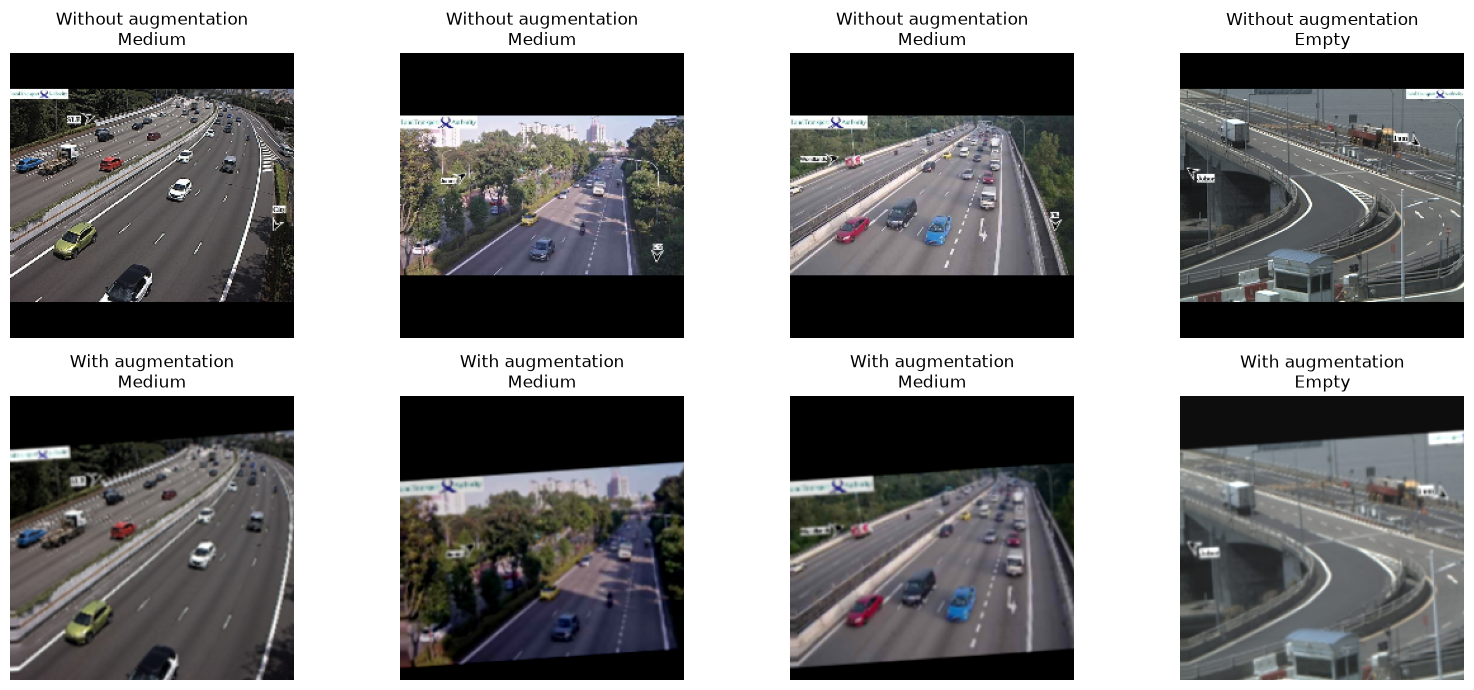

In [36]:
original_train_dataset, _, _ = create_datasets(
    augmentation=False,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)
augmented_train_dataset, _, _ = create_datasets(
    augmentation=True,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

original_images, original_labels = next(iter(original_train_dataset))
augmented_images, augmented_labels = next(iter(augmented_train_dataset))
num_images = min(4, int(original_images.shape[0]), int(augmented_images.shape[0]))
fig, axes = plt.subplots(2, num_images, figsize=(4 * num_images, 7), squeeze=False)

for index in range(num_images):
    original_class = CLASS_NAMES[np.argmax(original_labels[index].numpy())]
    augmented_class = CLASS_NAMES[np.argmax(augmented_labels[index].numpy())]

    axes[0, index].imshow(original_images[index].numpy())
    axes[0, index].set_title(f"Without augmentation\n{original_class}")
    axes[0, index].axis("off")

    axes[1, index].imshow(augmented_images[index].numpy())
    axes[1, index].set_title(f"With augmentation\n{augmented_class}")
    axes[1, index].axis("off")

plt.tight_layout()
plt.show()


## Dataset integrity check

Kiểm tra chỉ-đọc từng ảnh theo manifest. Loader hỗ trợ cả thư mục `Final Dataset/`
đã giải nén và fallback sang `traffic.zip`; không thay đổi split, nhãn hay file ảnh.


In [37]:
from src.data_loader import read_image

manifest_paths = {
    "TRAIN": project_dir / "data" / "manifests" / "train.csv",
    "VAL": project_dir / "data" / "manifests" / "val.csv",
    "TEST": project_dir / "data" / "manifests" / "test.csv",
}


def find_bad_images(csv_path):
    manifest = pd.read_csv(csv_path)
    bad_images = []
    for relative_path in manifest["image_path"]:
        try:
            read_image(str(project_dir / relative_path))
        except Exception as error:
            bad_images.append({"relative_path": str(relative_path), "error": str(error)})
    return bad_images


bad_images_by_split = {
    split: find_bad_images(csv_path) for split, csv_path in manifest_paths.items()
}
for split, bad_images in bad_images_by_split.items():
    print(f"{split}: {len(bad_images)} bad image(s)")
    for bad_image in bad_images[:20]:
        print(f"  {bad_image['relative_path']}: {bad_image['error']}")
    if len(bad_images) > 20:
        print(f"  ... {len(bad_images) - 20} more")


TRAIN: 0 bad image(s)
VAL: 0 bad image(s)
TEST: 0 bad image(s)


### Integrity result

Notebook này **không tự sửa hoặc ghi đè ảnh nguồn**. Nếu có ảnh lỗi, ghi lại
đường dẫn để review riêng thay vì sửa JPEG trong khi huấn luyện.


In [38]:
bad_count = sum(len(images) for images in bad_images_by_split.values())
if bad_count:
    print(f"WARNING: {bad_count} unreadable image(s); stop and review them before training.")
else:
    print("Integrity check passed. No image was modified.")


Integrity check passed. No image was modified.


### Re-check

Cell này chỉ hiển thị lại kết quả kiểm tra hiện tại; không có bước sửa ảnh tự động.


In [39]:
for split, bad_images in bad_images_by_split.items():
    print(f"{split}: {len(bad_images)} bad image(s)")


TRAIN: 0 bad image(s)
VAL: 0 bad image(s)
TEST: 0 bad image(s)


### Check available disk space


In [40]:
import shutil

total, used, free = shutil.disk_usage(project_dir)
print(f"Total: {total / 1024**3:.2f} GB")
print(f"Used : {used / 1024**3:.2f} GB")
print(f"Free : {free / 1024**3:.2f} GB")
if free < 2 * 1024**3:
    print("WARNING: Low disk space. Free some disk space before training.")


Total: 914.78 GB
Used : 620.15 GB
Free : 248.09 GB


In [41]:
# Initialize experiment tracking once before Experiments 1, 2, and 3.
experiment_models = {}
experiment_histories = {}
experiment_records = []


## 6. Experiment 1 — Deep CNN baseline

Thí nghiệm này dùng kiến trúc mới nhưng không augmentation và không class weights, nhằm quan sát ảnh hưởng của kiến trúc.

Epoch 1/20


/home/honganh/Documents/tempt/dl-traffic-density-classi/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791653884.660005  202177 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_53063__.123
I0000 00:00:1791653898.178747  202177 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
W0000 00:00:1791653910.388347  202177 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.05GiB (rounded to 1130531584)requested by op 
If the cause is memory fragmentation maybe the

 3/85 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step - accuracy: 0.3125 - loss: 1.6780 

W0000 00:00:1791653915.813680  202177 bfc_allocator.cc:383] Garbage collection: deallocate free memory regions (i.e., allocations) so that we can re-allocate a larger region to avoid OOM due to memory fragmentation. If you see this message frequently, you are running near the threshold of the available device memory and re-allocation may incur great performance overhead. You may try smaller batch sizes to observe the performance impact. Set TF_ENABLE_GPU_GARBAGE_COLLECTION=false if you'd like to disable this feature.


84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.5167 - loss: 1.1698

I0000 00:00:1791653921.028056  202173 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_53063__.123


85/85 ━━━━━━━━━━━━━━━━━━━━ 65s 328ms/step - accuracy: 0.5172 - loss: 1.1675 - val_accuracy: 0.3414 - val_loss: 3.1846 - val_macro_f1: 0.1018 - learning_rate: 0.0010
Epoch 2/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.6088 - loss: 0.9363 - val_accuracy: 0.3414 - val_loss: 3.4521 - val_macro_f1: 0.1018 - learning_rate: 0.0010
Epoch 3/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.6723 - loss: 0.7647 - val_accuracy: 0.3414 - val_loss: 3.6433 - val_macro_f1: 0.1018 - learning_rate: 0.0010
Epoch 4/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.7237 - loss: 0.7020 - val_accuracy: 0.4259 - val_loss: 2.3137 - val_macro_f1: 0.3465 - learning_rate: 0.0010
Epoch 5/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - accuracy: 0.7229 - loss: 0.6820 - val_accuracy: 0.5155 - val_loss: 2.2679 - val_macro_f1: 0.3026 - learning_rate: 0.0010
Epoch 6/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.7366 - loss: 0.6580 - val_accuracy: 0.6966 - val_loss: 0.7457 - val_macro_

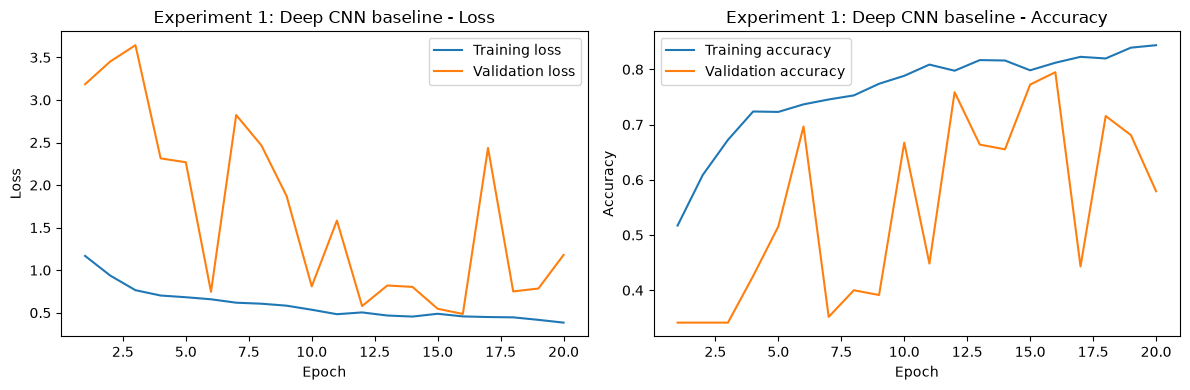

Best validation accuracy: 0.7948
Validation macro F1: 0.7984
Lowest validation loss: 0.4855


In [42]:
train_dataset_1, val_dataset_1, _ = create_datasets(
    augmentation=False, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
)
model_exp1 = build_deep_cnn()
model_exp1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy", metrics=["accuracy"],
    steps_per_execution=STEPS_PER_EXECUTION,
)
history_exp1 = model_exp1.fit(
    train_dataset_1, validation_data=val_dataset_1, epochs=EPOCHS,
    callbacks=make_callbacks(val_dataset_1, RUN_DIR / "exp1_best.keras"),
)
plot_history(history_exp1, "Experiment 1: Deep CNN baseline")
record_experiment(
    "Deep CNN baseline", history_exp1, model_exp1, val_dataset_1,
    augmentation=False, weighted=False,
)


## 7. Experiment 2 — Deep CNN + Augmentation

Kiến trúc và thiết lập giữ nguyên; chỉ bật augmentation. Mô hình mới được khởi tạo từ đầu.

Epoch 1/20


/home/honganh/Documents/tempt/dl-traffic-density-classi/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791654053.333658  202172 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_76990__.123


84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.4557 - loss: 1.3158

I0000 00:00:1791654065.391784  202172 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_76990__.123


85/85 ━━━━━━━━━━━━━━━━━━━━ 24s 187ms/step - accuracy: 0.4570 - loss: 1.3133 - val_accuracy: 0.3414 - val_loss: 1.7049 - val_macro_f1: 0.1018 - learning_rate: 0.0010
Epoch 2/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 10s 119ms/step - accuracy: 0.5334 - loss: 1.0922 - val_accuracy: 0.3414 - val_loss: 1.5936 - val_macro_f1: 0.1018 - learning_rate: 0.0010
Epoch 3/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.5988 - loss: 0.9476 - val_accuracy: 0.3414 - val_loss: 3.4659 - val_macro_f1: 0.1021 - learning_rate: 0.0010
Epoch 4/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 10s 121ms/step - accuracy: 0.6383 - loss: 0.8709 - val_accuracy: 0.4345 - val_loss: 1.3940 - val_macro_f1: 0.2629 - learning_rate: 0.0010
Epoch 5/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - accuracy: 0.6568 - loss: 0.8362 - val_accuracy: 0.6224 - val_loss: 0.8601 - val_macro_f1: 0.4115 - learning_rate: 0.0010
Epoch 6/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.6745 - loss: 0.7852 - val_accuracy: 0.5034 - val_loss: 1.1517 - 

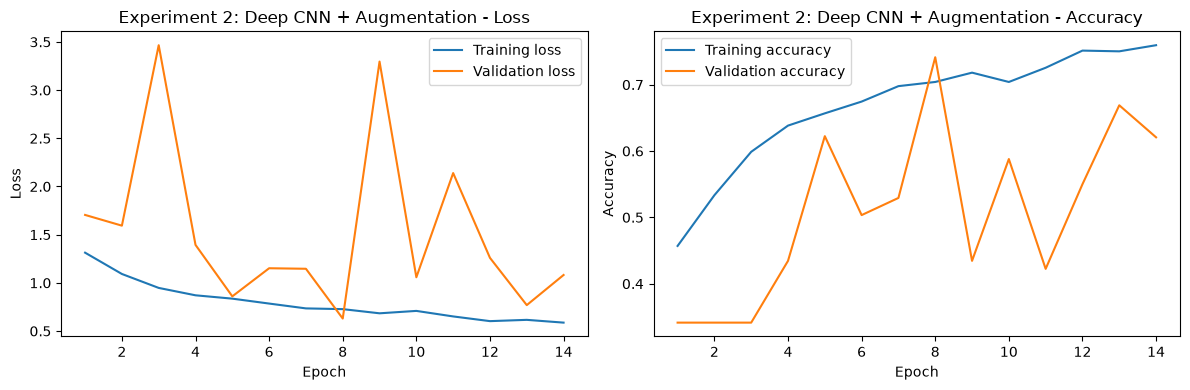

Best validation accuracy: 0.7414
Validation macro F1: 0.7196
Lowest validation loss: 0.6297


In [43]:
train_dataset_2, val_dataset_2, _ = create_datasets(
    augmentation=True, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
)
model_exp2 = build_deep_cnn()
model_exp2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy", metrics=["accuracy"],
    steps_per_execution=STEPS_PER_EXECUTION,
)
history_exp2 = model_exp2.fit(
    train_dataset_2, validation_data=val_dataset_2, epochs=EPOCHS,
    callbacks=make_callbacks(val_dataset_2, RUN_DIR / "exp2_best.keras"),
)
plot_history(history_exp2, "Experiment 2: Deep CNN + Augmentation")
record_experiment(
    "Deep CNN + Augmentation", history_exp2, model_exp2, val_dataset_2,
    augmentation=True, weighted=False,
)


In [44]:
from PIL import Image
import pandas as pd

train_manifest = pd.read_csv(project_dir / "data" / "manifests" / "train.csv")
bad_images = []

for rel_path in train_manifest["image_path"]:
    path = project_dir / rel_path
    try:
        with Image.open(path) as image:
            image.load()
    except Exception as e:
        bad_images.append((rel_path, str(e)))

bad_images

[]

In [45]:
import src.data_loader as dl

print(dl.__file__)
print(dl.PROJECT_DIR)
print(dl.MANIFEST_DIR)

train_manifest = pd.read_csv(dl.MANIFEST_DIR / "train.csv")
print(train_manifest["image_path"].isin([
    "Final Dataset/training/Traffic Jam/getty_523821065_98040.jpg",
    "Final Dataset/training/Traffic Jam/dreamstime_s_21795079.jpg",
]).to_list())

/home/honganh/Documents/tempt/dl-traffic-density-classi/src/data_loader.py
/home/honganh/Documents/tempt/dl-traffic-density-classi
/home/honganh/Documents/tempt/dl-traffic-density-classi/data/manifests
[False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False,

**Kết quả Experiment 2 — Deep CNN + Augmentation**

Kết quả validation được ghi tự động trong bảng tổng hợp sau khi chạy notebook. Experiment này chỉ bật augmentation; cùng callbacks và các thiết lập huấn luyện khác được giữ như những experiment còn lại.


## 8. Experiment 3 — Deep CNN + Augmentation + Class Weights

Thí nghiệm này thêm class weights vào cấu hình có augmentation để xem hiệu quả trên các lớp ít ảnh. Mô hình lại được khởi tạo mới.

Epoch 1/20


/home/honganh/Documents/tempt/dl-traffic-density-classi/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


I0000 00:00:1791654213.248522  202172 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_96623__.123


84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.3400 - loss: 1.5120

I0000 00:00:1791654223.799637  202173 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_96623__.123


85/85 ━━━━━━━━━━━━━━━━━━━━ 24s 172ms/step - accuracy: 0.3421 - loss: 1.5061 - val_accuracy: 0.3414 - val_loss: 1.8285 - val_macro_f1: 0.1019 - learning_rate: 0.0010
Epoch 2/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.4407 - loss: 1.2797 - val_accuracy: 0.4414 - val_loss: 1.3180 - val_macro_f1: 0.2436 - learning_rate: 0.0010
Epoch 3/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.5116 - loss: 1.1299 - val_accuracy: 0.3414 - val_loss: 2.5194 - val_macro_f1: 0.1018 - learning_rate: 0.0010
Epoch 4/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.5515 - loss: 1.0292 - val_accuracy: 0.3483 - val_loss: 1.7315 - val_macro_f1: 0.1239 - learning_rate: 0.0010
Epoch 5/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.5755 - loss: 0.9304 - val_accuracy: 0.5655 - val_loss: 1.0470 - val_macro_f1: 0.3716 - learning_rate: 0.0010
Epoch 6/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 10s 121ms/step - accuracy: 0.6177 - loss: 0.8766 - val_accuracy: 0.2328 - val_loss: 2.0373 - 

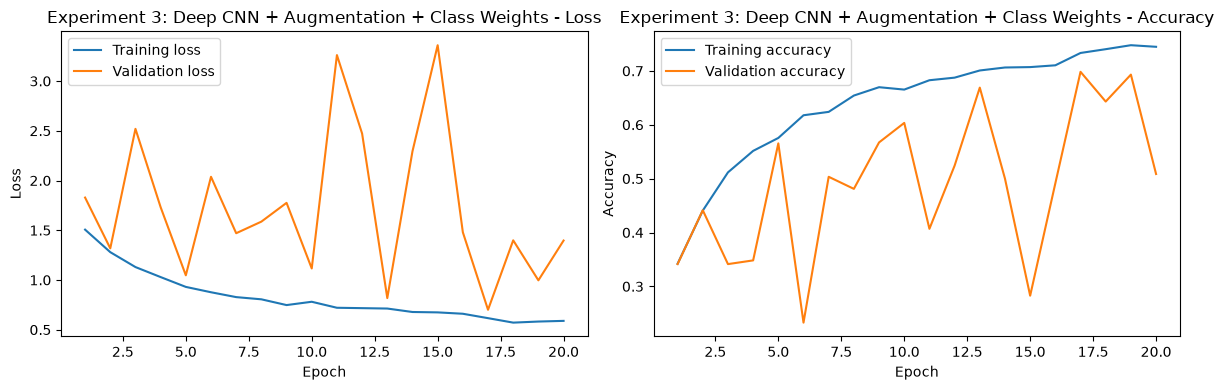

Best validation accuracy: 0.6983
Validation macro F1: 0.6970
Lowest validation loss: 0.7004


In [46]:
train_dataset_3, val_dataset_3, _ = create_datasets(
    augmentation=True, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
)
model_exp3 = build_deep_cnn()
model_exp3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy", metrics=["accuracy"],
    steps_per_execution=STEPS_PER_EXECUTION,
)
history_exp3 = model_exp3.fit(
    train_dataset_3, validation_data=val_dataset_3, epochs=EPOCHS,
    callbacks=make_callbacks(val_dataset_3, RUN_DIR / "exp3_best.keras"), class_weight=class_weights,
)
plot_history(history_exp3, "Experiment 3: Deep CNN + Augmentation + Class Weights")
record_experiment(
    "Deep CNN + Augmentation + Class Weights", history_exp3, model_exp3, val_dataset_3,
    augmentation=True, weighted=True,
)


**Kết quả Experiment 3 — Deep CNN + Augmentation + Class Weights**

Kết quả validation được ghi tự động trong bảng tổng hợp sau khi chạy notebook. Experiment này bật augmentation và class weights; các thiết lập còn lại được giữ nhất quán.


## 9. So sánh các thí nghiệm và chọn cấu hình cuối

In [47]:
experiment_results = pd.DataFrame(experiment_records)
experiment_results = experiment_results.sort_values(
    by=["Best Val Macro F1", "Best Val Accuracy", "Lowest Val Loss"],
    ascending=[False, False, True],
    ignore_index=True,
)
experiment_results


,Experiment,Augmentation,Class Weights,Best Val Accuracy,Best Val Macro F1,Lowest Val Loss,Epochs Trained
0,Deep CNN baseline,False,False,0.794828,0.798364,0.485497,20
1,Deep CNN + Augmentation,True,False,0.741379,0.719592,0.629749,14
2,Deep CNN + Augmentation + Class Weights,True,True,0.698276,0.697010,0.700412,20


In [48]:
selected_experiment = max(
    experiment_records,
    key=lambda row: (
        row["Best Val Macro F1"], row["Best Val Accuracy"], -row["Lowest Val Loss"]
    ),
)
final_model = experiment_models[selected_experiment["Experiment"]]
print("Selected final configuration:", selected_experiment["Experiment"])
print("Selection uses validation Macro F1, then accuracy and loss as tie-breakers.")


Selected final configuration: Deep CNN baseline
Selection uses validation Macro F1, then accuracy and loss as tie-breakers.


Model được chọn theo Validation Macro F1; Validation Accuracy và Loss dùng khi hòa. Test set chỉ dùng để đánh giá model đã chọn.


## 10. Đánh giá mô hình M2 trên test set

In [49]:
m2_result = evaluate_model(
    model=final_model,
    test_dataset=test_dataset,
    model_name="Deep Custom CNN",
)
m2_result


,Model,Accuracy,Precision,Recall,F1-score
0,Deep Custom CNN,0.8038,0.7829,0.8184,0.7957


Confusion matrix cho biết số mẫu thật của từng lớp được dự đoán vào mỗi lớp; classification report tóm tắt Precision, Recall và F1 trên test set. Có thể dùng hai kết quả này để xem nhóm lớp mật độ trung gian nào còn dễ nhầm lẫn.

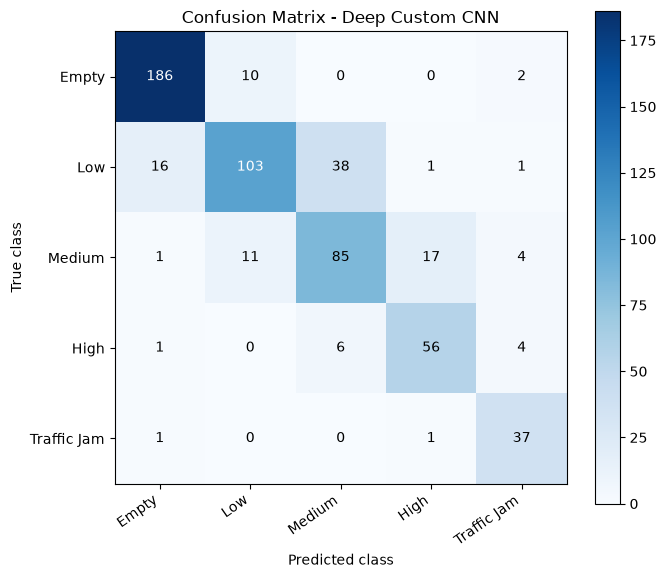

              precision    recall  f1-score   support

       Empty     0.9073    0.9394    0.9231       198
         Low     0.8306    0.6478    0.7279       159
      Medium     0.6589    0.7203    0.6883       118
        High     0.7467    0.8358    0.7887        67
 Traffic Jam     0.7708    0.9487    0.8506        39

    accuracy                         0.8038       581
   macro avg     0.7829    0.8184    0.7957       581
weighted avg     0.8082    0.8038    0.8016       581



In [50]:
if final_model is not None:
    pred_probs = final_model.predict(test_dataset, verbose=0)
    y_pred = np.argmax(pred_probs, axis=1)
    y_true = get_true_labels(test_dataset)

    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASS_NAMES)))
    plt.figure(figsize=(7, 6))
    plt.imshow(cm, interpolation="nearest", cmap="Blues")
    plt.title("Confusion Matrix - Deep Custom CNN")
    plt.colorbar()
    tick_positions = np.arange(len(CLASS_NAMES))
    plt.xticks(tick_positions, CLASS_NAMES, rotation=35, ha="right")
    plt.yticks(tick_positions, CLASS_NAMES)
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    threshold = cm.max() / 2 if cm.size else 0
    for row in range(cm.shape[0]):
        for column in range(cm.shape[1]):
            plt.text(column, row, format(cm[row, column], "d"),
                     ha="center", va="center",
                     color="white" if cm[row, column] > threshold else "black")
    plt.tight_layout()
    plt.show()

    print(classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    ))
else:
    print("Confusion matrix and classification report skipped because the selected model is unavailable.")


**Metrics theo từng lớp trên test set**

Classification report bên trên hiển thị precision, recall và F1-score cho từng lớp. Dùng các giá trị mới sau khi chạy notebook để xem lớp nào còn khó phân loại.


## 12. So sánh với Simple CNN của M1

M1 và M2 được so sánh trên cùng tập test bằng Accuracy, Macro Precision, Macro Recall và Macro F1-score. Các metric đều được tính bằng cùng hàm `evaluate_model()` để đảm bảo cách đánh giá nhất quán.


In [51]:
# Final test result from 01_simple_cnn.ipynb
m1_result = pd.DataFrame({
    "Model": ["Simple CNN"],
    "Accuracy": [0.7608],
    "Precision": [0.7459],
    "Recall": [0.7752],
    "F1-score": [0.7582],
})

comparison = pd.concat(
    [m1_result, m2_result],
    ignore_index=True,
)
comparison = comparison[["Model", "Accuracy", "Precision", "Recall", "F1-score"]]
comparison


,Model,Accuracy,Precision,Recall,F1-score
0,Simple CNN,0.7608,0.7459,0.7752,0.7582
1,Deep Custom CNN,0.8038,0.7829,0.8184,0.7957


In [52]:
m1_metrics = m1_result.iloc[0]
m2_metrics = m2_result.iloc[0]
comparison_delta = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
    ],
    "M1 Simple CNN": [
        m1_metrics["Accuracy"],
        m1_metrics["Precision"],
        m1_metrics["Recall"],
        m1_metrics["F1-score"],
    ],
    "M2 Deep Custom CNN": [
        m2_metrics["Accuracy"],
        m2_metrics["Precision"],
        m2_metrics["Recall"],
        m2_metrics["F1-score"],
    ],
})
comparison_delta["Difference (M2 - M1)"] = (
    comparison_delta["M2 Deep Custom CNN"]
    - comparison_delta["M1 Simple CNN"]
)
comparison_delta


,Metric,M1 Simple CNN,M2 Deep Custom CNN,Difference (M2 - M1)
0,Accuracy,0.7608,0.8038,0.0430
1,Precision,0.7459,0.7829,0.0370
2,Recall,0.7752,0.8184,0.0432
3,F1-score,0.7582,0.7957,0.0375


Giá trị `Difference (M2 - M1)` dương cho biết Deep Custom CNN đạt kết quả cao hơn Simple CNN ở metric tương ứng; giá trị âm cho biết kết quả thấp hơn.


## 13. Nhận xét

## 14. Lưu mô hình

In [53]:
if final_model is not None:
    model_path = RUN_DIR / "selected_deep_custom_cnn.keras"
    final_model.save(model_path)
    print(f"Model saved to: {model_path}")


Model saved to: /home/honganh/Documents/tempt/dl-traffic-density-classi/outputs/complex_cnn_notebook/selected_deep_custom_cnn.keras
